# Figure 1: Synthetic Data

Panel a:
- Amplitude difference image
- Axes in metres [m]

Panel b:
- Cross spectrum in phase (arg(XS)) [-pi,pi]
- Axes in rad/m/central_wavenumber [unitless]
- Lobes that are in energy above 10% of the max energy (|XS|) are encirled and not transparent. The other areas of the image are transparent

## Setup
Data and processing mirror `TimeLapse_Notebooks/Hypothesis_1.ipynb` exactly:
- migrated images come from the same cached npz archives as `load_study()` (cell 2), baseline = scenario 0, monitor = the chosen shift;
- both images are cropped laterally to $\pm 2.5\lambda$ around the scatterer apex, with the same envelope logic as `estimate_displacement()` (cell 4);
- the cross-spectrum $XS = B \cdot M^*$ comes from `helper_functions.WLS.estimate_shift_2d`, the same call the thesis results use;
- the WLS phase-plane fit uses **only the energy threshold** as its selection criterion (no $1.4\,k_{z,c}$ band): `helper_functions.migration.wls_phase_plane_fit` with an explicit mask $|XS| > 0.10 \max|XS|$, the same Tukey taper and no zero-padding, so it fits exactly the cross-spectrum shown in panel (b).

Run with the `gprmax` kernel (numpy / scipy / matplotlib / seaborn).

In [87]:
import sys
from fractions import Fraction
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import hilbert

# ── Repository paths ───────────────────────────────────────────────────────────────────
# Walk up from the working directory to the repo root (the folder holding
# TimeLapse_Notebooks/), so the notebook works whether Jupyter starts in New_Figures/
# or in the repo root.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'TimeLapse_Notebooks').is_dir())
NB_DIR = REPO_ROOT / 'TimeLapse_Notebooks'     # cached synthetic data + helper_functions
OUT_DIR = REPO_ROOT / 'New_Figures' / 'figures'

if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))
from helper_functions.WLS import estimate_shift_2d
from helper_functions.migration import wls_phase_plane_fit

# ── Physical constants (identical to Hypothesis_1.ipynb, cell 2) ───────────────────────
EPS_R = 3.15                                # relative permittivity of pure ice
V_ICE = 0.299792458 / np.sqrt(EPS_R)       # wave speed in ice [m/ns]
F_C_GHZ = 1.5                              # Ricker centre frequency [GHz]
LAM = V_ICE / F_C_GHZ                      # central wavelength in ice [m] (~0.1126 m)
KZ_C = 2 * np.pi / LAM                     # central wavenumber [rad/m]
FDTD_CELL_M = 0.001                        # gprMax grid cell; true shifts snap to it

sns.set_theme(style='ticks', context='paper', font_scale=1.0)
print(f'repo root: {REPO_ROOT}\nlambda = {LAM * 1e3:.3f} mm, k_zc = {KZ_C:.2f} rad/m')

repo root: c:\Users\Administrator\OneDrive\Thesis
lambda = 112.609 mm, k_zc = 55.80 rad/m


## Figure parameters
`AMP_THR` is the thesis amplitude threshold (`helper_functions/WLS.py`, §3 *The band-pass mask*), and here the **only** fitting criterion: a bin is opaque, outlined and used in the WLS fit where $|XS| > 0.10 \max|XS|$.

Without the band, the fit is only valid while no phase inside the lobes wraps past $\pm\pi$. On the Gazdag synthetics that holds up to $\lambda/2$ (lateral), $\lambda/8$ (vertical) and $(\lambda/8, \lambda/16)$ (diagonal); beyond that the estimate breaks down (e.g. vertical $\lambda/4$: $-1.0$ mm instead of 28 mm).

The k-window is $\pm 4\,k_{z,c}$ because in a zero-offset migrated **depth** image the wavelet is compressed by the two-way travel path, so the lobes peak at $|k_z| \approx 1.8\,k_{z,c}$ (not $1.0\,k_{z,c}$), and the 10 % lobes reach $|k_z| \approx 3.5\,k_{z,c}$.

In [88]:
MOVEMENTS = ['lateral', 'vertical', 'diagonal']  # one figure per entry
METHOD = 'Gazdag'      # 'Kirchhoff' | 'Gazdag' | 'Back-prop'
SHIFT_LAM = 0.0625       # shift along the primary axis [lambda] (x for lateral/diagonal,
                       # z for vertical): 0.5, 0.25, 0.125, 0.0625, 0.03125 ...

CROP_HW_LAM = 2.5      # lateral half-width of the analysis window [lambda] (as in H1)
SEARCH_LAM = 3.0       # half-width of the apex search window [lambda] (as in H1)
AMP_THR = 0.10         # opaque, outlined and fitted where |XS| > AMP_THR * max|XS|
ALPHA_LOW = 0.75       # alpha of the below-threshold bins
K_LIM = 4.0            # half-width of the plotted k-window [units of k_zc]
VIEW_HW_LAM = 1.0      # panel (a) display only: half-width [lambda] of the square zoom
                       # around the baseline scatterer; the XS is still computed on
                       # the full +-CROP_HW_LAM analysis window
MARG_FRAC = 0.28       # marginal strips on panel (b): thickness [fraction of panel]
PHASE_CMAP = 'RdGy_r'  # diverging phase map: black (-) -> white (0) -> red (+)
PHASE_LIM = None       # phase colour/axis range +-PHASE_LIM [rad]; None = auto, the
                       # largest |arg(XS)| in the lobes (small ramps fill the map)
MARG_PT_SIZE = 3.0     # marker size of the marginal scatter points (at FIG_SCALE = 1)
MARG_BG = '0.85'       # marginal-strip background, so near-0 (white) phases stay visible
FIG_SCALE = 1.4        # enlarges the whole figure; fonts, lines and markers scale with it
FIG_SIZE = (7.2 * FIG_SCALE, 3.8 * FIG_SCALE)  # inches (7.2 x 3.8 = two-column width)
DPI = 300

METHOD_KEYS = {'Kirchhoff': 'kirchhoff', 'Gazdag': 'gazdag', 'Back-prop': 'backprop'}

# Where each movement type's cache lives, and which npz keys carry its shift ladder
# (lambda units). Same files/keys as STUDIES in Hypothesis_1.ipynb. `primary` is the
# axis SHIFT_LAM refers to.
STUDIES = {
    'lateral': dict(
        root=NB_DIR / 'timelapse_study', migrated='migrated_results.npz',
        diff='difference_migrated_results.npz',
        shift_x='separation_lambda', shift_z=None, primary='x'),
    'vertical': dict(
        root=NB_DIR / 'vertical_timelapse_study', migrated='vertical_migrated_results.npz',
        diff='vertical_difference_migrated_results.npz',
        shift_x=None, shift_z='shift_lambda', primary='z'),
    'diagonal': dict(
        root=NB_DIR / 'diagonal_timelapse_study', migrated='diagonal_migrated_results.npz',
        diff='diagonal_difference_migrated_results.npz',
        shift_x='shift_lambda_x', shift_z='shift_lambda_y', primary='x'),
}

## Loading and cropping helpers

In [89]:
def fdtd_true(nominal_m):
    """Round a nominal displacement [m] to the nearest 1 mm FDTD cell -- the shift
    gprMax actually realised (same as fdtd_true() in Hypothesis_1.ipynb)."""
    return np.round(np.asarray(nominal_m, dtype=float) / FDTD_CELL_M) * FDTD_CELL_M


def lambda_label(frac):
    r"""0.25 -> '\lambda/4', 1.0 -> '\lambda', 2.0 -> '2\lambda' (mathtext, no $)."""
    f = Fraction(float(frac)).limit_denominator(64)
    if f == 0:
        return '0'
    if f.denominator == 1:
        return r'\lambda' if f.numerator == 1 else rf'{f.numerator}\lambda'
    num = '' if f.numerator == 1 else str(f.numerator)
    return rf'{num}\lambda/{f.denominator}'


def load_pair(movement, method, shift_lam):
    """Load the baseline and one monitor migrated image plus their grid axes.

    Returns a dict with base, mon (n_z, n_x), x [m], z [m], and the true dx/dz [m]
    and lambda fractions of the selected scenario.
    """
    cfg = STUDIES[movement]
    mig = np.load(cfg['root'] / cfg['migrated'])
    # diagonal_migrated_results.npz has no grid axes -> fall back to the diff archive
    diff = np.load(cfg['root'] / cfg['diff'])
    x = mig['x_traces'] if 'x_traces' in mig.files else diff['x_traces']
    z = mig['z_img'] if 'z_img' in mig.files else diff['z_img']

    n = len(mig['scenarios'])
    sx = mig[cfg['shift_x']] if cfg['shift_x'] else np.zeros(n)
    sz = mig[cfg['shift_z']] if cfg['shift_z'] else np.zeros(n)

    # Pick the scenario whose shift along the primary axis matches shift_lam
    ladder = sx if cfg['primary'] == 'x' else sz
    hits = np.flatnonzero(np.isclose(ladder, shift_lam))
    hits = hits[hits > 0]                      # index 0 is the baseline itself
    if hits.size == 0:
        raise ValueError(f'{movement}: no scenario with a {cfg["primary"]}-shift of '
                         f'{shift_lam} lambda; available: {sorted(set(ladder[1:]))}')
    i = int(hits[0])

    stack = mig[METHOD_KEYS[method]]
    return dict(base=np.nan_to_num(stack[0]), mon=np.nan_to_num(stack[i]), x=x, z=z,
                frac_x=float(sx[i]), frac_z=float(sz[i]),
                true_dx=float(fdtd_true(sx[i] * LAM)), true_dz=float(fdtd_true(sz[i] * LAM)))


def apex_crop_window(base, mon, x):
    """Lateral index range [ix_lo, ix_hi) of the +-CROP_HW_LAM*lambda analysis window.

    Port of estimate_displacement() in Hypothesis_1.ipynb: find the trace where the
    two envelopes differ most, then the baseline envelope peak within +-SEARCH_LAM
    lambda of it (the baseline apex), and centre the window there.
    """
    env_base = np.abs(hilbert(base, axis=0))
    env_mon = np.abs(hilbert(mon, axis=0))
    _, ix_d = np.unravel_index(np.argmax(np.abs(env_mon - env_base)), env_base.shape)

    lo_s, hi_s = np.searchsorted(x, [x[ix_d] - SEARCH_LAM * LAM, x[ix_d] + SEARCH_LAM * LAM])
    _, ix_loc = np.unravel_index(np.argmax(env_base[:, lo_s:hi_s]), env_base[:, lo_s:hi_s].shape)
    x_apex = x[lo_s + ix_loc]

    ix_lo, ix_hi = np.searchsorted(x, [x_apex - CROP_HW_LAM * LAM, x_apex + CROP_HW_LAM * LAM])
    return int(ix_lo), int(ix_hi)


def edge_extent(ax_h, ax_v):
    """imshow extent [left, right, bottom, top] whose pixel *edges* (not centres)
    bracket the sample axes, so every pixel sits exactly on its coordinate."""
    hh = 0.5 * (ax_h[1] - ax_h[0])
    hv = 0.5 * (ax_v[1] - ax_v[0])
    return [ax_h[0] - hh, ax_h[-1] + hh, ax_v[0] - hv, ax_v[-1] + hv]

## Panel data
- **(a)** difference image, monitor $-$ baseline, normalised by the baseline peak so the colour bar reads as a fraction of the reflector's own amplitude. Its axes are relative to the baseline scatterer $(x_0, z_0)$, taken as the peak of the baseline envelope, in units of $\lambda$. Markers show the baseline scatterer (origin) and the true monitor position $(\Delta x, \Delta z)/\lambda$ (FDTD-grid-rounded true shift).
- **(b)** $XS = \mathrm{FFT2}(b)\cdot\mathrm{FFT2}(m)^*$ (Tukey-tapered, from the thesis helper), `fftshift`-ed, with $k$-axes divided by $k_{z,c}$; phase $\arg(XS)$ and the alpha mask from $|XS|$. The displacement is the WLS fit of $\Phi = k_z\Delta z + k_x\Delta x + c$ over the above-threshold bins only, weighted by $|XS|$.

In [90]:
def compute_panels(movement, method, shift_lam):
    d = load_pair(movement, method, shift_lam)

    # 1. Crop both images to the analysis window (what the WLS fit actually sees)
    ix_lo, ix_hi = apex_crop_window(d['base'], d['mon'], d['x'])
    x_c, z = d['x'][ix_lo:ix_hi], d['z']
    base_c = d['base'][:, ix_lo:ix_hi]
    mon_c = d['mon'][:, ix_lo:ix_hi]
    dx_g, dz_g = float(x_c[1] - x_c[0]), float(z[1] - z[0])

    # 2. Panel (a): difference image relative to the baseline peak, and the baseline
    #    scatterer position (x0, z0) = peak of the baseline envelope -> axis origin
    diff_img = (mon_c - base_c) / np.abs(base_c).max()
    env_base = np.abs(hilbert(base_c, axis=0))
    iz0, ix0 = np.unravel_index(np.argmax(env_base), env_base.shape)
    x0, z0 = float(x_c[ix0]), float(z[iz0])

    # 3. Panel (b): cross-spectrum from the thesis helper (its own band-limited
    #    estimate is discarded -- the fit below uses the energy threshold only)
    _, _, _, XS, kz_ax, kx_ax = estimate_shift_2d(base_c, mon_c, dz_g, dx_g, KZ_C)

    # WLS phase-plane fit over the above-threshold bins only (no k-band), on the same
    # cross-spectrum: same Tukey taper (alpha 0.15), no zero-padding (pad_fac=1), mask
    # on the unshifted FFT grid; the DC bin is excluded as in the thesis helper
    KZ, KX = np.meshgrid(kz_ax, kx_ax, indexing='ij')
    fit_mask = (np.abs(XS) > AMP_THR * np.abs(XS).max()) & ((np.abs(KZ) + np.abs(KX)) > 0)
    dz_est, dx_est, _, _ = wls_phase_plane_fit(base_c, mon_c, dz_g, dx_g, KZ_C,
                                               taper='tukey', tukey_alpha=0.15,
                                               pad_fac=1, mask=fit_mask)

    # fftshift -> monotonic k-axes with DC in the middle; normalise by k_zc
    XS = np.fft.fftshift(XS)
    kz_n = np.fft.fftshift(kz_ax) / KZ_C
    kx_n = np.fft.fftshift(kx_ax) / KZ_C

    phase = np.angle(XS)                      # arg(XS) in (-pi, pi]
    amp_rel = np.abs(XS) / np.abs(XS).max()   # |XS| / max|XS|, 0..1

    # 2-D alpha array: opaque where |XS| > thesis threshold, faded elsewhere
    alpha = np.where(amp_rel > AMP_THR, 1.0, ALPHA_LOW)

    return dict(d, x_c=x_c, z=z, x0=x0, z0=z0, diff_img=diff_img, XS=XS, phase=phase, amp_rel=amp_rel,
                alpha=alpha, kz_n=kz_n, kx_n=kx_n, dz_est=dz_est, dx_est=dx_est)

## Plotting
Panel (b) shows the raw phase $\arg(XS)$ with a diverging colour map, scaled to the largest $|\arg(XS)|$ inside the lobes (or to `PHASE_LIM`), so even a $\lambda/16$ ramp uses the full contrast range.

Its two marginal strips plot the **raw** $\arg(XS)$ of every above-threshold bin ($|XS| >$ `AMP_THR` $\cdot \max|XS|$), i.e. exactly the points the WLS phase-plane fit uses, against $k_x$ (top) and $k_z$ (right), coloured by phase on the same colour map and range as the colour bar (grey strip background so phases near 0 stay visible). The slope of each point cloud is the gradient of the phase plane along that axis, i.e. $\Delta x$ (top) and $\Delta z$ (right).

The Hermitian symmetry $\arg XS(-\mathbf{k}) = -\arg XS(\mathbf{k})$ means the two lobes carry phases of opposite sign. Over $k_z$ they always separate into two clouds; over $k_x$ they coincide only when $\Delta z = 0$, so the top strip shows one cloud for lateral motion and two mirrored clouds once there is a vertical component.

In [91]:
def plot_figure(p, movement, method, shift_lam):
    # Fonts and line widths scale with the figure (seaborn 'paper' context x FIG_SCALE)
    sns.set_theme(style='ticks', context='paper', font_scale=FIG_SCALE,
                  rc={'lines.linewidth': 1.0 * FIG_SCALE})
    plt.rcParams.update({'savefig.dpi': DPI, 'image.interpolation': 'nearest'})
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=FIG_SIZE, layout='constrained')
    # Inset axes (colour bars, marginal strips) reserve no layout space, so keep a
    # fixed gap between the panels for panel (a)'s colour-bar label
    fig.get_layout_engine().set(wspace=0.14)

    # (a) Difference image on axes relative to the baseline scatterer (x0, z0), in
    #     units of lambda.
    #     Depth increases downwards -> origin='upper' with the extent's bottom edge at
    #     the deepest sample.
    x_rel = (p['x_c'] - p['x0']) / LAM
    z_rel = (p['z'] - p['z0']) / LAM
    ext_a = edge_extent(x_rel, z_rel)
    ext_a = [ext_a[0], ext_a[1], ext_a[3], ext_a[2]]  # [xmin, xmax, zmax, zmin]
    vmax_diff = np.abs(p['diff_img']).max()
    im_a = ax_a.imshow(p['diff_img'], extent=ext_a, origin='upper', aspect='equal',
                       cmap='RdBu_r', vmin=-vmax_diff, vmax=vmax_diff)
    # Zoom the view (not the data) onto the area of change around the scatterer
    ax_a.set_xlim(-VIEW_HW_LAM, VIEW_HW_LAM)
    ax_a.set_ylim(VIEW_HW_LAM, -VIEW_HW_LAM)
    ax_a.set_xlabel(r'$(x - x_0)\,/\,\lambda$')
    ax_a.set_ylabel(r'$(z - z_0)\,/\,\lambda$')
    # Baseline scatterer (origin) and true monitor position (grid-rounded true shift)
    mk_kw = dict(ms=4.5 * FIG_SCALE, mew=1.0 * FIG_SCALE, ls='none')
    ax_a.plot(0, 0, marker='o', mfc='none', mec='k', label='baseline', **mk_kw)
    ax_a.plot(p['true_dx'] / LAM, p['true_dz'] / LAM, marker='x', mec='k',
              label='monitor (true)', **mk_kw)
    ax_a.legend(loc='lower left', fontsize=6.5 * FIG_SCALE, handletextpad=0.3,
                borderpad=0.4, framealpha=0.9)
    ax_a.set_title('(a) Difference: monitor $-$ baseline', loc='left')
    cb_a = fig.colorbar(im_a, cax=ax_a.inset_axes([1.04, 0, 0.05, 1]))
    cb_a.set_label(r'$\Delta$amplitude / max$|$baseline$|$')

    # (b) Cross-spectrum phase: k_z increases upwards -> origin='lower'.
    sel = p['amp_rel'] > AMP_THR                       # above-threshold bins
    # Symmetric phase range: fixed PHASE_LIM, or auto = largest |arg(XS)| in the lobes,
    # so a small sub-wavelength ramp still spans the whole diverging colour map
    ph_lim = PHASE_LIM if PHASE_LIM is not None else 1.05 * np.abs(p['phase'][sel]).max()
    im_b = ax_b.imshow(p['phase'], extent=edge_extent(p['kx_n'], p['kz_n']), origin='lower',
                       aspect='equal', cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim,
                       alpha=p['alpha'])
    # Outline the above-threshold lobes (contour uses pixel-centre coordinates)
    ax_b.contour(p['kx_n'], p['kz_n'], p['amp_rel'], levels=[AMP_THR],
                 colors='tab:green', linewidths=1.8 * FIG_SCALE)
    ax_b.set_xlim(-K_LIM, K_LIM)
    ax_b.set_ylim(-K_LIM, K_LIM)
    ax_b.set_xlabel(r'$k_x \,/\, k_{z,c}$')
    ax_b.set_ylabel(r'$k_z \,/\, k_{z,c}$')

    # Marginals: the RAW arg(XS) of every above-threshold bin -- exactly the points
    # the WLS phase-plane fit uses -- against k_x (top) and k_z (right); each cloud's
    # slope is the phase-plane gradient (= displacement) along that axis.
    KZ_n, KX_n = np.meshgrid(p['kz_n'], p['kx_n'], indexing='ij')
    ax_top = ax_b.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_b)
    ax_rgt = ax_b.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_b)
    # Points coloured by their phase on the same colour map + range as the colour bar
    sc_kw = dict(c=p['phase'][sel], cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim,
                 s=MARG_PT_SIZE * FIG_SCALE ** 2, linewidths=0, rasterized=True)
    ax_top.scatter(KX_n[sel], p['phase'][sel], **sc_kw)
    ax_rgt.scatter(p['phase'][sel], KZ_n[sel], **sc_kw)
    for ax in (ax_top, ax_rgt):
        ax.set_facecolor(MARG_BG)
    ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
    ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)

    # Strip ticks at a round value well inside +-ph_lim, so the end labels don't
    # collide with the main axes' tick labels at the panel corners
    t = float(f'{0.6 * ph_lim:.1g}')
    ph_ticks = [-t, 0, t]
    ph_lbls = [f'{-t:g}', '0', f'{t:g}']
    ax_top.set_ylim(-ph_lim, ph_lim)
    ax_top.set_yticks(ph_ticks, ph_lbls, fontsize=6.5 * FIG_SCALE)
    ax_top.set_ylabel(r'$\arg(XS)$')
    ax_top.tick_params(labelbottom=False)
    ax_rgt.set_xlim(-ph_lim, ph_lim)
    ax_rgt.set_xticks(ph_ticks, ph_lbls, fontsize=6.5 * FIG_SCALE)
    ax_rgt.set_xlabel(r'$\arg(XS)$ (rad)')
    ax_rgt.tick_params(labelleft=False)

    # Align panel (a) with the phase map itself (not the map + top strip)
    ax_a.set_anchor('S')
    ax_b.set_anchor('S')

    ax_top.set_title(r'(b) Cross-spectrum phase $\arg(XS)$', loc='left')
    cb_b = fig.colorbar(im_b, cax=ax_b.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]))
    cb_b.set_label('Phase (rad)')
    cb_b.solids.set_alpha(1.0)  # colour bar shows the opaque colours

    # True vs WLS-estimated displacement, in the (empty) upper-left corner of (a)
    def _mm(v):
        return round(v * 1e3, 1) + 0.0        # + 0.0 turns -0.0 into 0.0

    shift_txt = (rf'$\Delta x$: ${lambda_label(p["frac_x"])}$ = {p["true_dx"] * 1e3:.0f} mm, '
                 rf'est. {_mm(p["dx_est"]):.1f} mm' + '\n' +
                 rf'$\Delta z$: ${lambda_label(p["frac_z"])}$ = {p["true_dz"] * 1e3:.0f} mm, '
                 rf'est. {_mm(p["dz_est"]):.1f} mm')
    ax_a.text(0.03, 0.97, shift_txt, transform=ax_a.transAxes, fontsize=6.5 * FIG_SCALE,
              va='top', ha='left',
              bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.7', lw=0.5 * FIG_SCALE))

    # Save, then show inline
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    shift_tag = str(Fraction(shift_lam).limit_denominator(64)).replace('/', 'over')
    out = OUT_DIR / f'fig1_{movement}_{METHOD_KEYS[method]}_{shift_tag}lambda.png'
    fig.savefig(out, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return out

## Generate Figure 1
One figure per movement type in `MOVEMENTS`, saved to `New_Figures/figures/` (dpi = 300).

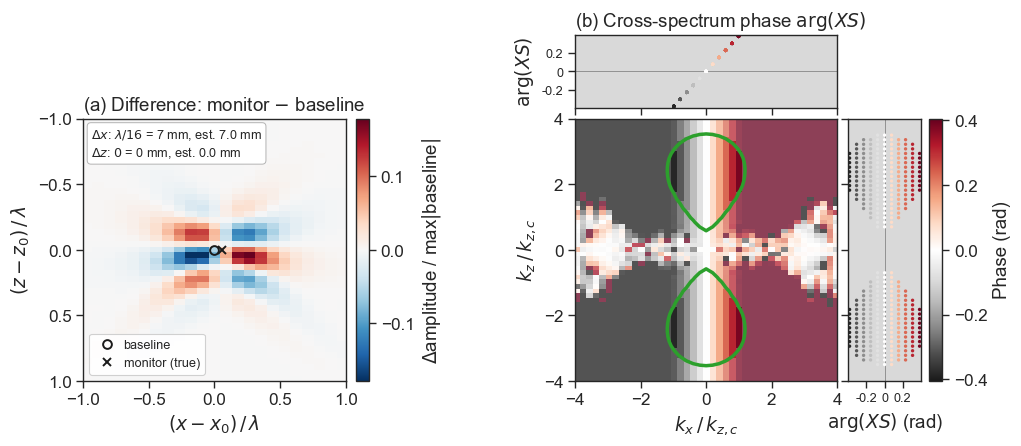

lateral  Gazdag    shift=0.0625 lambda | dx true    7.0 est   7.00 mm | dz true    0.0 est   0.00 mm -> fig1_lateral_gazdag_1over16lambda.png


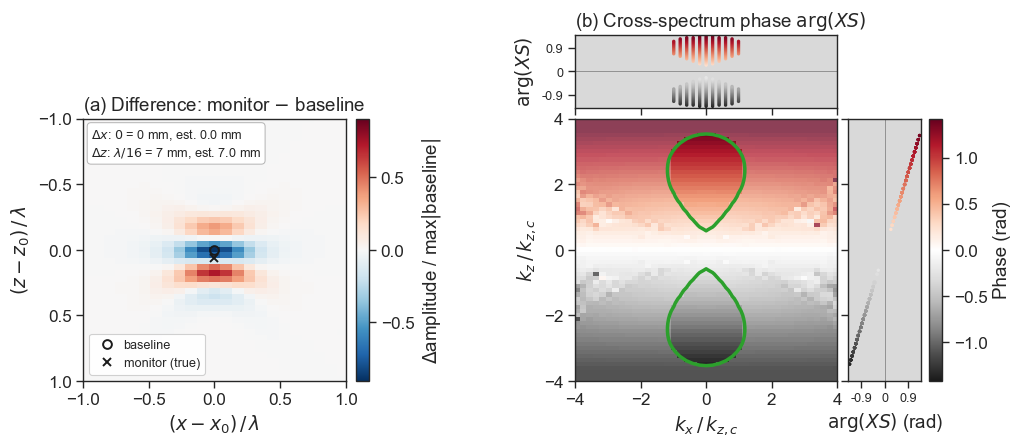

vertical Gazdag    shift=0.0625 lambda | dx true    0.0 est   0.00 mm | dz true    7.0 est   6.99 mm -> fig1_vertical_gazdag_1over16lambda.png


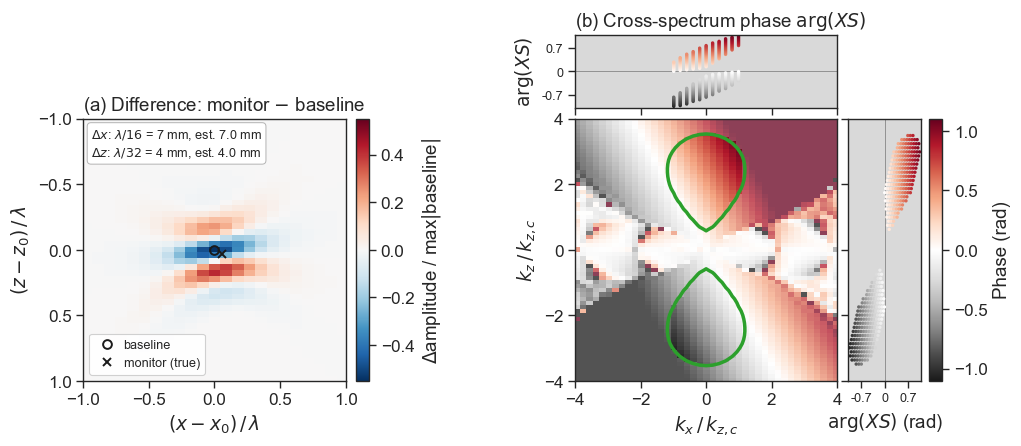

diagonal Gazdag    shift=0.0625 lambda | dx true    7.0 est   7.00 mm | dz true    4.0 est   3.99 mm -> fig1_diagonal_gazdag_1over16lambda.png


In [92]:
for mv in MOVEMENTS:
    p = compute_panels(mv, METHOD, SHIFT_LAM)
    out = plot_figure(p, mv, METHOD, SHIFT_LAM)
    print(f'{mv:8s} {METHOD:9s} shift={SHIFT_LAM:g} lambda | '
          f'dx true {p["true_dx"] * 1e3:6.1f} est {p["dx_est"] * 1e3:6.2f} mm | '
          f'dz true {p["true_dz"] * 1e3:6.1f} est {p["dz_est"] * 1e3:6.2f} mm -> {out.name}')

# Figure 2: Field Data 1
Field-data counterpart of Figure 1, replacing the 2x2 WLS workflow figure of `TimeLapse_Notebooks/FieldData_Final_Pipeline.ipynb` (cell 27, `build_wls_workflow_figure`): Gazdag migration, profiles 1 → 2 (`STAGE_PAIRS[0]`).

Panel a:
- Amplitude difference image (monitor $-$ baseline), with the manual B-scan pick outlined
- Axes in metres [m] ($\lambda = v/f_0 = 1$ m in the field, so metres are also wavelengths)

Panel b:
- Cross-spectrum phase $\arg(XS)$ on the same padded $(k_z, k_x)$ grid the k-space pick was painted on
- Axes normalised by the central wavenumber $k_c = 2\pi f_0 / v$ [unitless]; only $k_x \ge 0$ is shown, because in the borehole geometry the wavelet runs along the radial axis, so the Hermitian mirror lobe sits at $-k_x$
- The **manual k-space pick** (the population the field WLS fit actually uses) is opaque and outlined, and its raw phases fill the marginal strips; everything else is faded

**Data.** The arrays come from `New_Figures/export_fielddata_pair.py`, which runs only the pipeline's compute steps for profiles 0, 1, 2 in the `gdp` env (whose matplotlib cannot render text) and saves `New_Figures/data/fielddata_gazdag_1_2.npz`. The displacement is the pipeline's §7.4 estimate (WLS on the manual pick, `wls_pow = 3`, identical to `fielddata_stage_displacements.csv`).

**Orientation.** Depth increases downwards in panel (a), and $k_z$ in panel (b) is the wavenumber along physical depth ($= -k_z$ of the image-row axis used inside the fit), so a phase slope along $k_z$ has the same sign as the reported $\Delta z$ (+ = deeper).

Run the Figure 1 setup, parameter and helper cells first: this section reuses their styling (`PHASE_CMAP`, `ALPHA_LOW`, `MARG_*`, `FIG_SCALE`, `edge_extent`, ...).

In [96]:
FD_NPZ = REPO_ROOT / 'New_Figures' / 'data' / 'fielddata_gazdag_2_3.npz'
FD_VIEW_PAD = 1.0       # panel (a): margin [m] around the B-scan pick (= 1 lambda in the field)
FD_KX_LIM = None        # panel (b): k_x window (lo, hi) [k_c]; None = pick bbox + FD_K_PAD
FD_KZ_LIM = None        # panel (b): k_z window (lo, hi) [k_c]; None = pick bbox + FD_K_PAD
                        # (only k_x >= 0 exists in the export; cell 27 used (0, 2) x +-0.65)
FD_K_PAD = 0.75         # auto k-window margin, as a fraction of the pick's span per axis
FD_ALPHA_LOW = 0.2      # alpha outside the k-space pick: the field phase there is
                        # incoherent, so it is faded harder than Figure 1's ALPHA_LOW

In [97]:
def load_field_panels(npz_path):
    '''Load the exported field pair and put both panels in the figure's orientation:
    depth increasing downwards (rows flipped so row 0 = shallowest) and k_z along
    physical depth (= -k_z of the image-row axis, rows flipped so k_z increases upwards).'''
    f = np.load(npz_path)
    lam, kc = float(f['lam']), float(f['kz_cent'])

    # Panel (a): Gazdag images have DEPTH_AXIS decreasing with row (row 0 = 85 m)
    depth = f['depth_axis'][::-1]                       # increasing, shallow -> deep
    diff_img = f['diff'][::-1] / np.abs(f['base']).max()
    bscan_mask = f['bscan_mask'][::-1]

    # Panel (b): cropped, fftshifted cross-spectrum on the k-space pick's own grid
    kz_n = -f['kz_ax'][::-1] / kc                       # physical-depth k_z, increasing
    kx_n = f['kx_ax'] / kc
    phase = f['phi'][::-1]
    pick = f['kspace_mask'][::-1]

    return dict(x=f['x_img'], depth=depth, diff_img=diff_img, bscan_mask=bscan_mask,
                kz_n=kz_n, kx_n=kx_n, phase=phase, pick=pick,
                alpha=np.where(pick, 1.0, FD_ALPHA_LOW), lam=lam,
                dx_est=float(f['dx_est']), dz_est=float(f['dz_phys']),
                n_mask=int(f['n_mask']), method=str(f['method']),
                run_a=int(f['run_a']), run_b=int(f['run_b']))


fd = load_field_panels(FD_NPZ)
print(f"{fd['method']} {fd['run_a']}->{fd['run_b']}: {fd['n_mask']} picked k-cells, "
      f"dx = {fd['dx_est']:+.4f} m, dz = {fd['dz_est']:+.4f} m (+ = deeper)")

gazdag 2->3: 620 picked k-cells, dx = -0.1101 m, dz = -0.6728 m (+ = deeper)


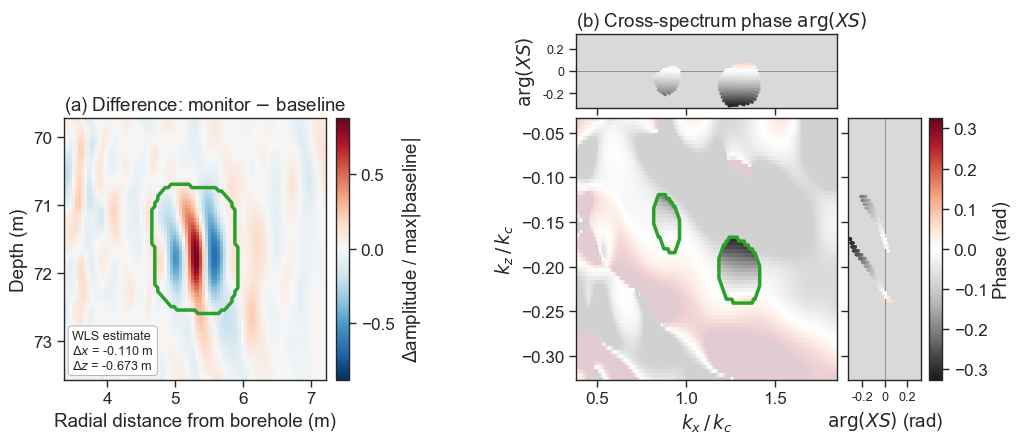

saved fig2_field_gazdag_2_to_3.png


In [98]:
def plot_field_figure(p):
    sns.set_theme(style='ticks', context='paper', font_scale=FIG_SCALE,
                  rc={'lines.linewidth': 1.0 * FIG_SCALE})
    plt.rcParams.update({'savefig.dpi': DPI, 'image.interpolation': 'nearest'})
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=FIG_SIZE, layout='constrained')
    fig.get_layout_engine().set(wspace=0.14)
    pick_kw = dict(colors='tab:green', linewidths=1.8 * FIG_SCALE)

    # (a) Difference image, depth increasing downwards (row 0 = shallowest after the
    #     flip in load_field_panels -> origin='upper', extent top = shallowest edge)
    ext = edge_extent(p['x'], p['depth'])               # [x0, x1, d_shallow, d_deep]
    ext_a = [ext[0], ext[1], ext[3], ext[2]]            # [xmin, xmax, bottom=deep, top=shallow]
    vmax_diff = np.abs(p['diff_img']).max()
    im_a = ax_a.imshow(p['diff_img'], extent=ext_a, origin='upper', aspect='equal',
                       cmap='RdBu_r', vmin=-vmax_diff, vmax=vmax_diff)
    ax_a.contour(p['x'], p['depth'], p['bscan_mask'].astype(float), levels=[0.5], **pick_kw)
    # Zoom the view onto the B-scan pick (+ FD_VIEW_PAD), as a square window
    rows, cols = np.nonzero(p['bscan_mask'])
    xc = 0.5 * (p['x'][cols.min()] + p['x'][cols.max()])
    zc = 0.5 * (p['depth'][rows.min()] + p['depth'][rows.max()])
    hw = 0.5 * max(np.ptp(p['x'][cols]), np.ptp(p['depth'][rows])) + FD_VIEW_PAD
    ax_a.set_xlim(xc - hw, xc + hw)
    ax_a.set_ylim(zc + hw, zc - hw)                     # deeper at the bottom
    ax_a.set_xlabel('Radial distance from borehole (m)')
    ax_a.set_ylabel('Depth (m)')
    ax_a.set_title('(a) Difference: monitor $-$ baseline', loc='left')
    cb_a = fig.colorbar(im_a, cax=ax_a.inset_axes([1.04, 0, 0.05, 1]))
    cb_a.set_label(r'$\Delta$amplitude / max$|$baseline$|$')
    est_txt = ('WLS estimate\n'                              # Delta z: + = deeper
               rf"$\Delta x$ = {p['dx_est']:+.3f} m" + '\n' +
               rf"$\Delta z$ = {p['dz_est']:+.3f} m")
    ax_a.text(0.03, 0.03, est_txt, transform=ax_a.transAxes, fontsize=6.5 * FIG_SCALE,
              va='bottom', ha='left',
              bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.7', lw=0.5 * FIG_SCALE))

    # (b) Cross-spectrum phase: opaque + outlined = manual k-space pick (the fit population)
    sel = p['pick']
    ph_lim = PHASE_LIM if PHASE_LIM is not None else 1.05 * np.abs(p['phase'][sel]).max()
    im_b = ax_b.imshow(p['phase'], extent=edge_extent(p['kx_n'], p['kz_n']), origin='lower',
                       aspect='auto', cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim,
                       alpha=p['alpha'])
    ax_b.contour(p['kx_n'], p['kz_n'], sel.astype(float), levels=[0.5], **pick_kw)
    # k-window: fixed FD_K*_LIM, or the pick's bounding box + FD_K_PAD of its span
    def _win(k, lim):
        if lim is not None:
            return lim
        lo, hi = k.min(), k.max()
        pad = FD_K_PAD * (hi - lo)
        return lo - pad, hi + pad
    rows, cols = np.nonzero(sel)
    ax_b.set_xlim(*_win(p['kx_n'][cols], FD_KX_LIM))
    ax_b.set_ylim(*_win(p['kz_n'][rows], FD_KZ_LIM))
    ax_b.set_box_aspect(1)                              # square panel, like Figure 1
    ax_b.set_xlabel(r'$k_x \,/\, k_c$')
    ax_b.set_ylabel(r'$k_z \,/\, k_c$')

    # Marginals: RAW arg(XS) of every picked bin (exactly the WLS fit points) against
    # k_x (top) and k_z (right), coloured on the same scale as the colour bar
    KZ_n, KX_n = np.meshgrid(p['kz_n'], p['kx_n'], indexing='ij')
    ax_top = ax_b.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_b)
    ax_rgt = ax_b.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_b)
    sc_kw = dict(c=p['phase'][sel], cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim,
                 s=MARG_PT_SIZE * FIG_SCALE ** 2, linewidths=0, rasterized=True)
    ax_top.scatter(KX_n[sel], p['phase'][sel], **sc_kw)
    ax_rgt.scatter(p['phase'][sel], KZ_n[sel], **sc_kw)
    for ax in (ax_top, ax_rgt):
        ax.set_facecolor(MARG_BG)
    ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
    ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
    t = float(f'{0.6 * ph_lim:.1g}')
    ph_ticks, ph_lbls = [-t, 0, t], [f'{-t:g}', '0', f'{t:g}']
    ax_top.set_ylim(-ph_lim, ph_lim)
    ax_top.set_yticks(ph_ticks, ph_lbls, fontsize=6.5 * FIG_SCALE)
    ax_top.set_ylabel(r'$\arg(XS)$')
    ax_top.tick_params(labelbottom=False)
    ax_rgt.set_xlim(-ph_lim, ph_lim)
    ax_rgt.set_xticks(ph_ticks, ph_lbls, fontsize=6.5 * FIG_SCALE)
    ax_rgt.set_xlabel(r'$\arg(XS)$ (rad)')
    ax_rgt.tick_params(labelleft=False)

    ax_a.set_anchor('S')
    ax_b.set_anchor('S')
    ax_top.set_title(r'(b) Cross-spectrum phase $\arg(XS)$', loc='left')
    cb_b = fig.colorbar(im_b, cax=ax_b.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]))
    cb_b.set_label('Phase (rad)')
    cb_b.solids.set_alpha(1.0)

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    out = OUT_DIR / f"fig2_field_{p['method']}_{p['run_a']}_to_{p['run_b']}.png"
    fig.savefig(out, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return out


print('saved', plot_field_figure(fd).name)